In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_excel("Employee_Resignation_Analysis.xlsx")

In [3]:
df.head()

,EmployeeID,Name,Gender,Age,Department,JobRole,DateOfJoining,DateOfExit,PerformanceRating,ResignationReason,LastWorkingLocation,Tenure (Years),YearOfExit
0,1,Sneha Sharma,Female,37,HR,HR Specialist,2007-04-20,2023-06-23,5,Better Opportunity,Chennai,16.186301,2023
1,2,Ravi Sharma,Male,27,HR,HR Specialist,2016-05-02,2024-01-31,1,Work-life Balance,Hyderabad,7.753425,2024
2,3,Vikas Singh,Male,50,Marketing,SEO Specialist,2005-02-23,2023-03-02,2,Retirement,Bangalore,18.030137,2023
3,4,John Patel,Male,43,Sales,Sales Executive,2013-07-10,2015-08-10,3,Low Job Satisfaction,Chennai,2.084932,2015
4,5,John Sharma,Female,56,Sales,Sales Manager,2006-10-08,2020-02-24,3,Work-life Balance,Kolkata,13.389041,2020


In [4]:
df.shape

(5000, 13)

In [5]:
df.columns.tolist()

['EmployeeID',
 'Name',
 'Gender',
 'Age',
 'Department',
 'JobRole',
 'DateOfJoining',
 'DateOfExit',
 'PerformanceRating',
 'ResignationReason',
 'LastWorkingLocation',
 'Tenure (Years)',
 'YearOfExit']

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   EmployeeID           5000 non-null   int64         
 1   Name                 5000 non-null   str           
 2   Gender               5000 non-null   str           
 3   Age                  5000 non-null   int64         
 4   Department           5000 non-null   str           
 5   JobRole              5000 non-null   str           
 6   DateOfJoining        5000 non-null   datetime64[us]
 7   DateOfExit           5000 non-null   datetime64[us]
 8   PerformanceRating    5000 non-null   int64         
 9   ResignationReason    5000 non-null   str           
 10  LastWorkingLocation  5000 non-null   str           
 11  Tenure (Years)       5000 non-null   float64       
 12  YearOfExit           5000 non-null   int64         
dtypes: datetime64[us](2), float64(1), int64(4), 

In [7]:
df.isnull().sum()

EmployeeID             0
Name                   0
Gender                 0
Age                    0
Department             0
JobRole                0
DateOfJoining          0
DateOfExit             0
PerformanceRating      0
ResignationReason      0
LastWorkingLocation    0
Tenure (Years)         0
YearOfExit             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["EmployeeID"].duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,EmployeeID,Age,DateOfJoining,DateOfExit,PerformanceRating,Tenure (Years),YearOfExit
count,5000.000000,5000.000000,5000,5000,5000.000000,5000.000000,5000.000000
mean,2500.500000,40.836400,2013-02-03 01:41:39.840000,2019-07-23 23:06:43.200000,2.974800,6.470938,2019.049400
min,1.000000,22.000000,2005-01-01 00:00:00,2006-01-04 00:00:00,1.000000,1.000000,2006.000000
25%,1250.750000,31.000000,2009-01-26 00:00:00,2016-12-08 12:00:00,2.000000,3.199315,2016.000000
50%,2500.500000,41.000000,2013-02-14 00:00:00,2020-07-12 12:00:00,3.000000,5.484932,2020.000000
75%,3750.250000,50.000000,2017-03-15 00:00:00,2022-11-19 00:00:00,4.000000,9.077397,2022.000000
max,5000.000000,60.000000,2020-12-29 00:00:00,2024-12-31 00:00:00,5.000000,19.884932,2024.000000
std,1443.520003,11.257717,NaN,NaN,1.412149,4.094454,4.146806


In [11]:
categorical_columns = [
    "Gender", "Department", "JobRole",
    "ResignationReason", "LastWorkingLocation"
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts())


Gender:
Gender
Male      2520
Female    2480
Name: count, dtype: int64

Department:
Department
Finance       878
Operations    851
Marketing     837
IT            823
HR            813
Sales         798
Name: count, dtype: int64

JobRole:
JobRole
Accountant               442
Logistics Coordinator    437
Financial Analyst        436
Marketing Executive      430
Operations Manager       414
HR Manager               408
SEO Specialist           407
HR Specialist            405
Sales Manager            400
Sales Executive          398
IT Support               282
Software Engineer        275
System Admin             266
Name: count, dtype: int64

ResignationReason:
ResignationReason
Better Opportunity      1017
Retirement              1004
Work-life Balance       1000
Low Job Satisfaction     997
Personal Reasons         982
Name: count, dtype: int64

LastWorkingLocation:
LastWorkingLocation
Delhi        741
Hyderabad    737
Bangalore    729
Pune         721
Kolkata      708
Chennai      

In [12]:
print("Joining date range:")
print(df["DateOfJoining"].min(), "to", df["DateOfJoining"].max())

print("\nExit date range:")
print(df["DateOfExit"].min(), "to", df["DateOfExit"].max())

Joining date range:
2005-01-01 00:00:00 to 2020-12-29 00:00:00

Exit date range:
2006-01-04 00:00:00 to 2024-12-31 00:00:00


In [13]:
invalid_dates = df[df["DateOfExit"] < df["DateOfJoining"]]

print("Invalid date records:", len(invalid_dates))

Invalid date records: 0


In [14]:
print("Minimum age:", df["Age"].min())
print("Maximum age:", df["Age"].max())
print("\nAge distribution:")
print(df["Age"].value_counts().sort_index())

Minimum age: 22
Maximum age: 60

Age distribution:
Age
22    130
23    125
24    140
25    141
26    134
27    125
28    138
29    148
30    134
31    125
32    113
33    113
34    105
35    138
36    129
37    138
38    113
39    122
40    118
41    131
42    143
43    121
44    126
45    121
46    145
47    155
48    130
49    129
50    124
51    129
52    126
53    124
54    119
55    122
56    135
57    120
58    145
59    109
60    117
Name: count, dtype: int64


In [15]:
print("Performance ratings:")
print(df["PerformanceRating"].value_counts().sort_index())

Performance ratings:
PerformanceRating
1    1033
2     985
3    1022
4     995
5     965
Name: count, dtype: int64


In [16]:
calculated_tenure = (
    df["DateOfExit"] - df["DateOfJoining"]
).dt.days / 365

difference = (
    df["Tenure (Years)"] - calculated_tenure
).abs()

print("Maximum tenure difference:", difference.max())
print("Records with tenure mismatch:", (difference > 0.001).sum())

Maximum tenure difference: 0.0
Records with tenure mismatch: 0


In [17]:
analysis_df = df.copy()

In [18]:
text_columns = analysis_df.select_dtypes(include="object").columns

for col in text_columns:
    analysis_df[col] = analysis_df[col].str.strip()

C:\Users\Welcome\AppData\Local\Temp\ipykernel_14012\701229825.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = analysis_df.select_dtypes(include="object").columns


In [19]:
text_columns = analysis_df.select_dtypes(include=["str"]).columns

for col in text_columns:
    analysis_df[col] = analysis_df[col].str.strip()

print("Text columns cleaned successfully!")

Text columns cleaned successfully!


In [20]:
print("Unique Employee IDs:", analysis_df["EmployeeID"].nunique())
print("Total records:", len(analysis_df))

Unique Employee IDs: 5000
Total records: 5000


In [21]:
print(analysis_df["YearOfExit"].value_counts().sort_index())

YearOfExit
2006     13
2007     20
2008     36
2009     68
2010     88
2011    113
2012    114
2013    155
2014    200
2015    195
2016    270
2017    263
2018    331
2019    396
2020    442
2021    522
2022    590
2023    573
2024    611
Name: count, dtype: int64


In [22]:
print("Total resignations:", len(analysis_df))
print("Average age:", round(analysis_df["Age"].mean(), 2))
print("Average tenure:", round(analysis_df["Tenure (Years)"].mean(), 2))
print("Male employees:", (analysis_df["Gender"] == "Male").sum())
print("Female employees:", (analysis_df["Gender"] == "Female").sum())

Total resignations: 5000
Average age: 40.84
Average tenure: 6.47
Male employees: 2520
Female employees: 2480


In [23]:
department_counts = analysis_df["Department"].value_counts()

print(department_counts)

Department
Finance       878
Operations    851
Marketing     837
IT            823
HR            813
Sales         798
Name: count, dtype: int64


In [24]:
reason_counts = analysis_df["ResignationReason"].value_counts()

print(reason_counts)

ResignationReason
Better Opportunity      1017
Retirement              1004
Work-life Balance       1000
Low Job Satisfaction     997
Personal Reasons         982
Name: count, dtype: int64


In [25]:
gender_counts = analysis_df["Gender"].value_counts()

print(gender_counts)

Gender
Male      2520
Female    2480
Name: count, dtype: int64


In [26]:
performance_counts = analysis_df["PerformanceRating"].value_counts().sort_index()

print(performance_counts)

PerformanceRating
1    1033
2     985
3    1022
4     995
5     965
Name: count, dtype: int64


In [27]:
jobrole_counts = analysis_df["JobRole"].value_counts()

print(jobrole_counts)

JobRole
Accountant               442
Logistics Coordinator    437
Financial Analyst        436
Marketing Executive      430
Operations Manager       414
HR Manager               408
SEO Specialist           407
HR Specialist            405
Sales Manager            400
Sales Executive          398
IT Support               282
Software Engineer        275
System Admin             266
Name: count, dtype: int64


In [28]:
role_reason = pd.crosstab(
    analysis_df["JobRole"],
    analysis_df["ResignationReason"]
)

role_reason

ResignationReason,Better Opportunity,Low Job Satisfaction,Personal Reasons,Retirement,Work-life Balance
JobRole,,,,,
Accountant,90,89,84,88,91
Financial Analyst,94,100,86,85,71
HR Manager,83,71,89,85,80
HR Specialist,88,78,80,81,78
IT Support,51,63,46,66,56
Logistics Coordinator,88,88,81,90,90
Marketing Executive,89,88,78,87,88
Operations Manager,91,69,83,96,75
SEO Specialist,83,70,90,77,87


In [29]:
department_gender = pd.crosstab(
    analysis_df["Department"],
    analysis_df["Gender"]
)

department_gender

Gender,Female,Male
Department,,
Finance,435,443
HR,410,403
IT,398,425
Marketing,399,438
Operations,442,409
Sales,396,402


In [30]:
performance_department = pd.crosstab(
    analysis_df["Department"],
    analysis_df["PerformanceRating"]
)

performance_department

PerformanceRating,1,2,3,4,5
Department,,,,,
Finance,195,174,147,195,167
HR,163,174,159,173,144
IT,165,157,163,159,179
Marketing,182,142,198,163,152
Operations,177,169,184,156,165
Sales,151,169,171,149,158


In [31]:
yearly_resignations = (
    analysis_df.groupby("YearOfExit")
    .size()
    .sort_index()
)

print(yearly_resignations)

YearOfExit
2006     13
2007     20
2008     36
2009     68
2010     88
2011    113
2012    114
2013    155
2014    200
2015    195
2016    270
2017    263
2018    331
2019    396
2020    442
2021    522
2022    590
2023    573
2024    611
dtype: int64


In [32]:
print("Minimum tenure:", analysis_df["Tenure (Years)"].min())
print("Maximum tenure:", analysis_df["Tenure (Years)"].max())
print("\nTenure statistics:")
print(analysis_df["Tenure (Years)"].describe())

Minimum tenure: 1.0
Maximum tenure: 19.884931506849316

Tenure statistics:
count    5000.000000
mean        6.470938
std         4.094454
min         1.000000
25%         3.199315
50%         5.484932
75%         9.077397
max        19.884932
Name: Tenure (Years), dtype: float64


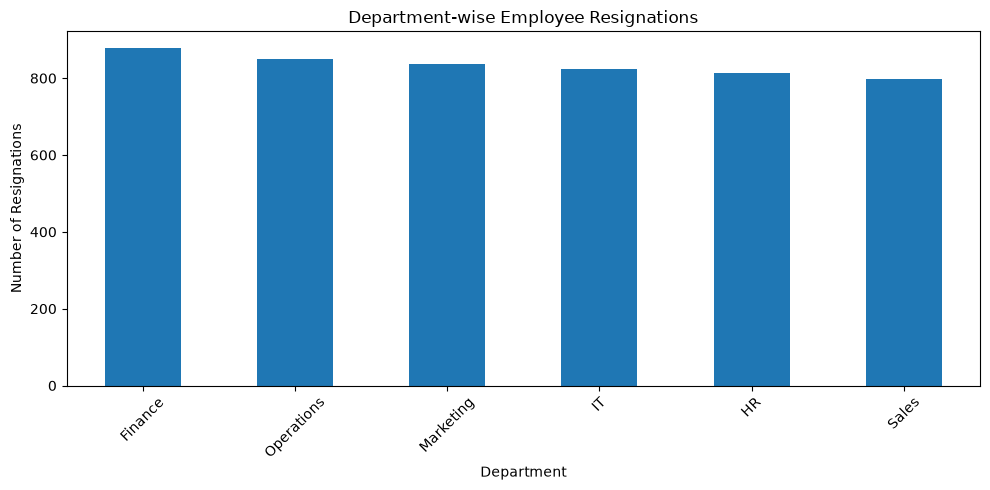

In [33]:
plt.figure(figsize=(10, 5))

department_counts.plot(kind="bar")

plt.title("Department-wise Employee Resignations")
plt.xlabel("Department")
plt.ylabel("Number of Resignations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

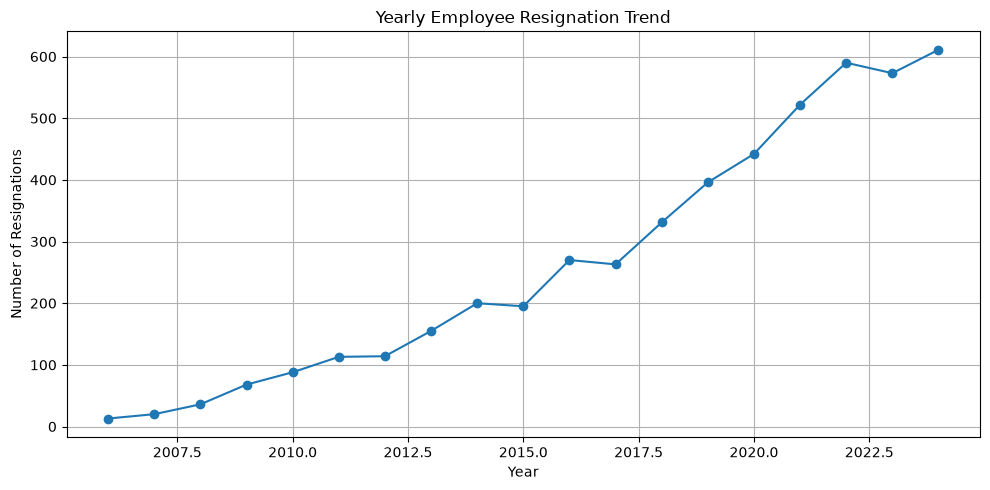

In [34]:
plt.figure(figsize=(10, 5))

yearly_resignations.plot(kind="line", marker="o")

plt.title("Yearly Employee Resignation Trend")
plt.xlabel("Year")
plt.ylabel("Number of Resignations")
plt.grid(True)
plt.tight_layout()
plt.show()

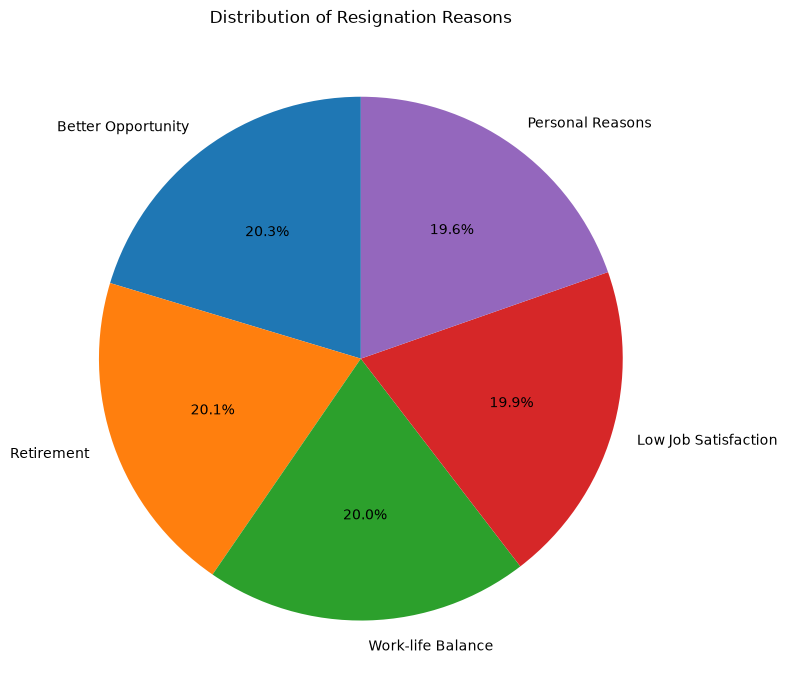

In [35]:
plt.figure(figsize=(8, 8))

reason_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Resignation Reasons")
plt.ylabel("")
plt.tight_layout()
plt.show()

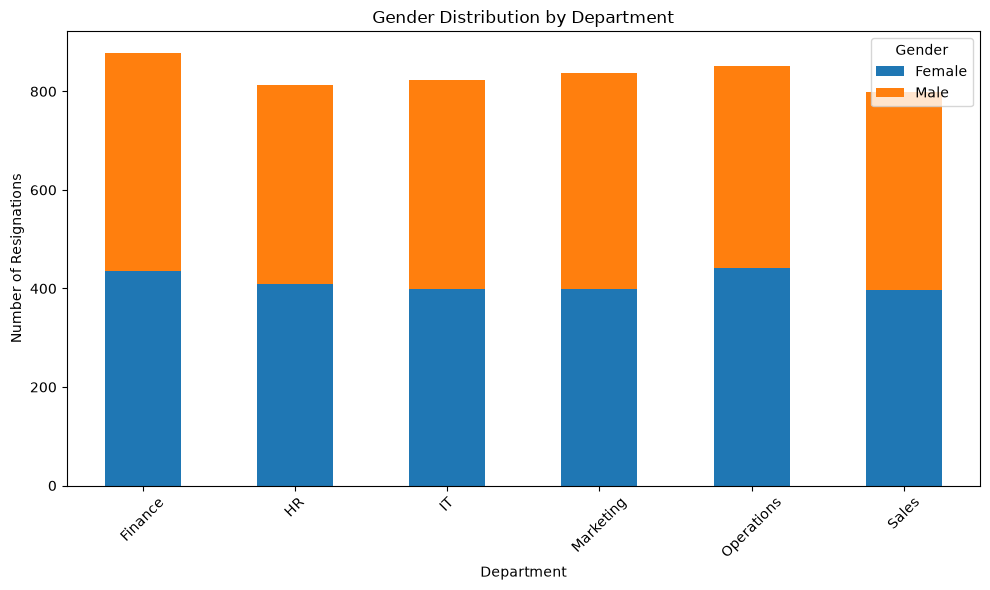

In [36]:
department_gender.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Gender Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Number of Resignations")
plt.xticks(rotation=45)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

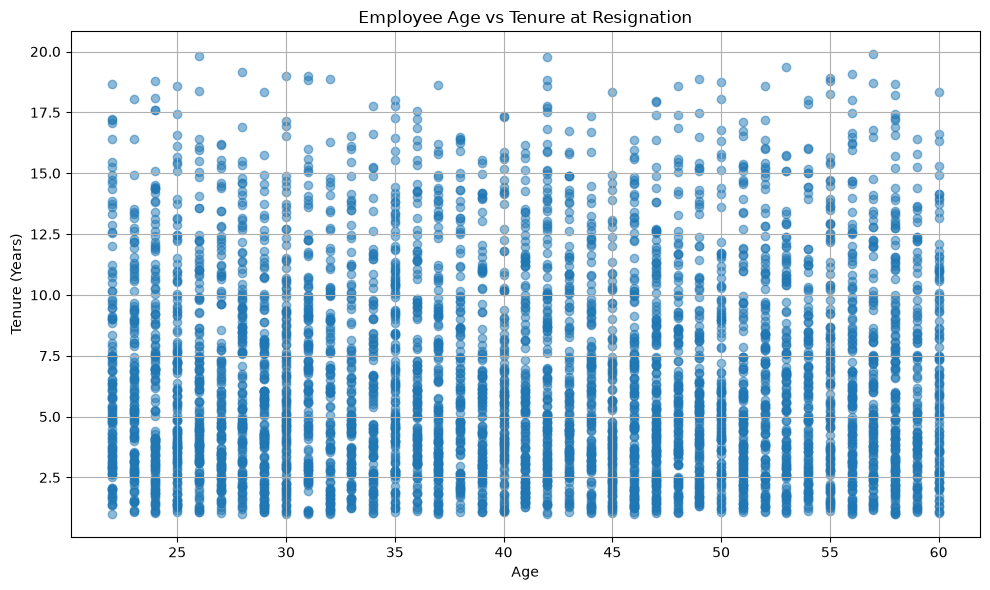

In [37]:
plt.figure(figsize=(10, 6))

plt.scatter(
    analysis_df["Age"],
    analysis_df["Tenure (Years)"],
    alpha=0.5
)

plt.title("Employee Age vs Tenure at Resignation")
plt.xlabel("Age")
plt.ylabel("Tenure (Years)")
plt.grid(True)
plt.tight_layout()
plt.show()

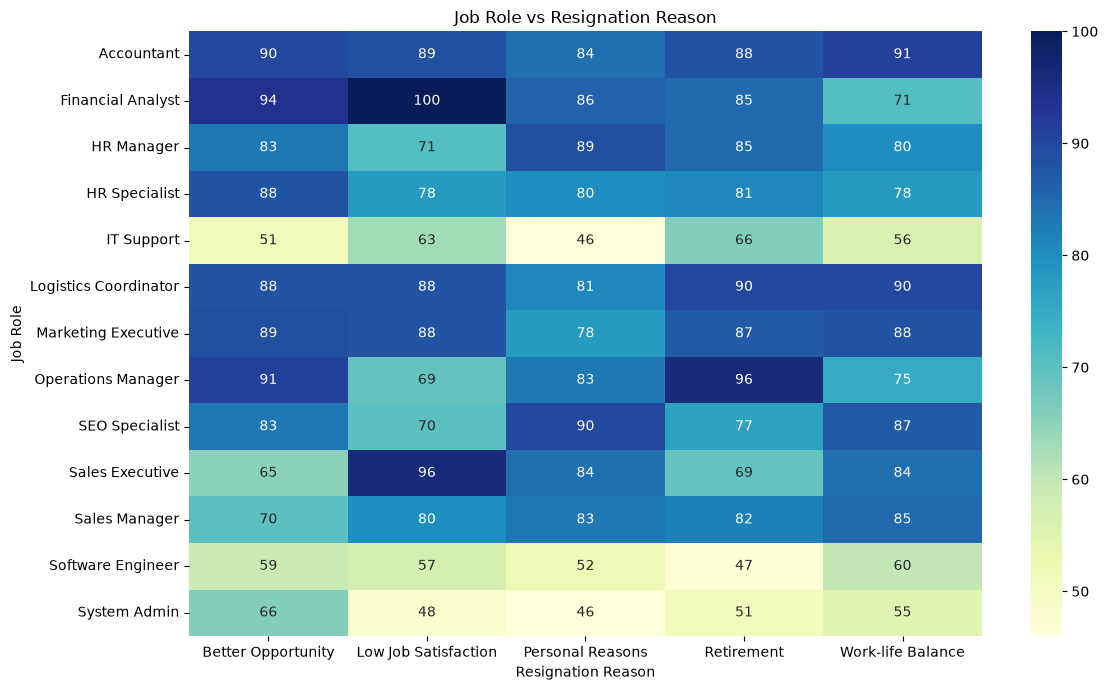

In [38]:
plt.figure(figsize=(12, 7))

sns.heatmap(role_reason, annot=True, fmt="d", cmap="YlGnBu")

plt.title("Job Role vs Resignation Reason")
plt.xlabel("Resignation Reason")
plt.ylabel("Job Role")
plt.tight_layout()
plt.show()

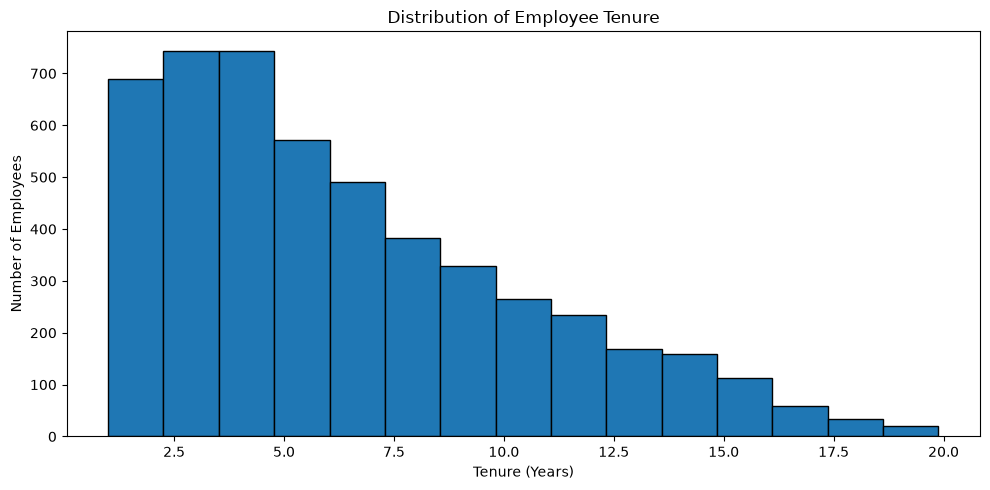

In [39]:
plt.figure(figsize=(10, 5))

plt.hist(analysis_df["Tenure (Years)"], bins=15, edgecolor="black")

plt.title("Distribution of Employee Tenure")
plt.xlabel("Tenure (Years)")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

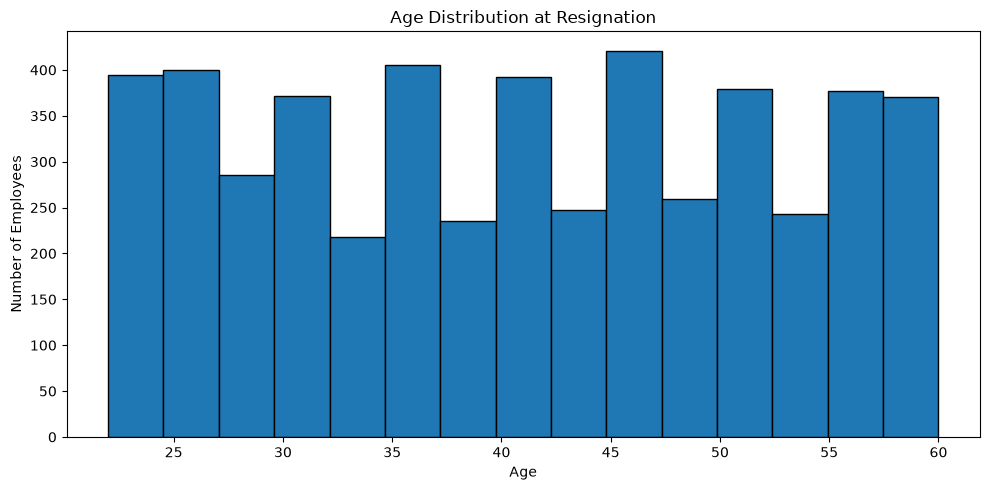

In [40]:
plt.figure(figsize=(10, 5))

plt.hist(analysis_df["Age"], bins=15, edgecolor="black")

plt.title("Age Distribution at Resignation")
plt.xlabel("Age")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

In [41]:
summary = pd.DataFrame({
    "Metric": [
        "Total Resignations",
        "Average Age",
        "Average Tenure",
        "Male Resignations",
        "Female Resignations"
    ],
    "Value": [
        len(analysis_df),
        round(analysis_df["Age"].mean(), 2),
        round(analysis_df["Tenure (Years)"].mean(), 2),
        (analysis_df["Gender"] == "Male").sum(),
        (analysis_df["Gender"] == "Female").sum()
    ]
})

summary

,Metric,Value
0,Total Resignations,5000.00
1,Average Age,40.84
2,Average Tenure,6.47
3,Male Resignations,2520.00
4,Female Resignations,2480.00


In [42]:
department_summary = pd.DataFrame({
    "Resignations": department_counts,
    "Percentage": (
        department_counts / len(analysis_df) * 100
    ).round(2)
})

department_summary

,Resignations,Percentage
Department,,
Finance,878,17.56
Operations,851,17.02
Marketing,837,16.74
IT,823,16.46
HR,813,16.26
Sales,798,15.96


In [43]:
top_department = department_counts.idxmax()
top_department_count = department_counts.max()

print("Department with highest resignations:", top_department)
print("Number of resignations:", top_department_count)

Department with highest resignations: Finance
Number of resignations: 878


In [44]:
top_reason = reason_counts.idxmax()
top_reason_count = reason_counts.max()

print("Most common resignation reason:", top_reason)
print("Number of resignations:", top_reason_count)

Most common resignation reason: Better Opportunity
Number of resignations: 1017


In [45]:
tenure_by_reason = (
    analysis_df.groupby("ResignationReason")["Tenure (Years)"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print(tenure_by_reason)

ResignationReason
Retirement              6.57
Personal Reasons        6.53
Low Job Satisfaction    6.46
Better Opportunity      6.42
Work-life Balance       6.37
Name: Tenure (Years), dtype: float64


In [46]:
age_by_department = (
    analysis_df.groupby("Department")["Age"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

print(age_by_department)

Department
Operations    41.43
Sales         41.25
Marketing     41.14
IT            40.68
Finance       40.40
HR            40.12
Name: Age, dtype: float64


In [47]:
recommendations = [
    "Investigate departments with higher resignation counts.",
    "Review employee engagement and workplace satisfaction.",
    "Explore career growth and compensation opportunities.",
    "Study tenure patterns to identify employee retention challenges.",
    "Examine performance trends among employees who resigned."
]

for number, recommendation in enumerate(recommendations, 1):
    print(f"{number}. {recommendation}")

1. Investigate departments with higher resignation counts.
2. Review employee engagement and workplace satisfaction.
3. Explore career growth and compensation opportunities.
4. Study tenure patterns to identify employee retention challenges.
5. Examine performance trends among employees who resigned.


In [48]:
yearly_summary = yearly_resignations.reset_index()
yearly_summary.columns = ["YearOfExit", "Resignation_Count"]

yearly_summary

,YearOfExit,Resignation_Count
0,2006,13
1,2007,20
2,2008,36
3,2009,68
4,2010,88
5,2011,113
6,2012,114
7,2013,155
8,2014,200
9,2015,195


In [49]:
reason_summary = reason_counts.reset_index()
reason_summary.columns = ["ResignationReason", "Resignation_Count"]

reason_summary

,ResignationReason,Resignation_Count
0,Better Opportunity,1017
1,Retirement,1004
2,Work-life Balance,1000
3,Low Job Satisfaction,997
4,Personal Reasons,982


In [50]:
with pd.ExcelWriter("Python_Resignation_Analysis_Report.xlsx", engine="openpyxl") as writer:
    summary.to_excel(writer, sheet_name="Overall_Summary", index=False)
    department_summary.to_excel(writer, sheet_name="Department_Analysis")
    reason_summary.to_excel(writer, sheet_name="Resignation_Reasons", index=False)
    yearly_summary.to_excel(writer, sheet_name="Yearly_Trend", index=False)
    tenure_by_reason.to_frame().to_excel(writer, sheet_name="Tenure_By_Reason")
    age_by_department.to_frame().to_excel(writer, sheet_name="Age_By_Department")

print("Excel report exported successfully!")

Excel report exported successfully!


In [51]:
import os

print(os.path.exists("Python_Resignation_Analysis_Report.xlsx"))

True


In [52]:
os.listdir()

['.ipynb_checkpoints',
 'Employee_Resignation_Analysis.xlsx',
 'Employee_Resignation_Analysis_Final.ipynb',
 'Python_Resignation_Analysis_Report.xlsx']

# Employee Resignation Data Analysis Using Python

## Project Overview

This project analyzes employee resignation data using Python.
The objective is to identify patterns and trends in employee
resignations through statistical analysis and data visualization.

## Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- OpenPyXL
- Jupyter Notebook

## Dataset

The dataset contains 5,000 employee resignation records
and 13 columns.

## Analysis Performed

1. Loaded and inspected the employee resignation dataset.
2. Checked missing values and duplicate records.
3. Verified employee tenure calculations.
4. Analyzed resignations by department, gender, and reason.
5. Examined yearly resignation trends.
6. Studied age and tenure distributions.
7. Compared resignation reasons across job roles and departments.

## Data Visualizations

The project includes the following visualizations:

- Department-wise resignation bar chart
- Yearly resignation trend line chart
- Resignation reason pie chart
- Gender distribution by department
- Age vs. tenure scatter plot
- Job role vs. resignation reason heatmap
- Employee tenure distribution histogram
- Employee age distribution histogram

## Key Findings

- Total employee resignations analyzed: 5,000.
- Average employee age: 40.84 years.
- Average employee tenure: 6.47 years.
- Male resignations: 2,520.
- Female resignations: 2,480.
- Better Opportunity was the most common resignation reason.
- Finance recorded the highest number of resignations among departments.

## Recommendations

- Investigate departments with higher resignation counts.
- Review employee engagement and workplace satisfaction.
- Explore career growth and compensation opportunities.
- Study tenure patterns to identify employee retention challenges.
- Examine performance trends among employees who resigned.

## Project Files

- Employee_Resignation_Analysis.xlsx — Original dataset
- Employee_Resignation_Analysis_Final.ipynb — Python analysis notebook
- Python_Resignation_Analysis_Report.xlsx — Exported analysis report

In [54]:
readme_content = """
# Employee Resignation Data Analysis Using Python

## Project Overview
This project analyzes 5,000 employee resignation records
to identify patterns and trends in employee resignations.

## Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- OpenPyXL
- Jupyter Notebook

## Analysis Performed
- Dataset inspection and data quality checks
- Missing value and duplicate checks
- Employee tenure verification
- Department-wise resignation analysis
- Gender-wise resignation analysis
- Resignation reason analysis
- Yearly resignation trends
- Age and tenure analysis

## Visualizations
- Department-wise resignation bar chart
- Yearly resignation trend line chart
- Resignation reason pie chart
- Gender distribution by department
- Age vs. tenure scatter plot
- Job role vs. resignation reason heatmap
- Age and tenure histograms

## Key Findings
- Total resignations: 5,000
- Average age: 40.84 years
- Average tenure: 6.47 years
- Male resignations: 2,520
- Female resignations: 2,480
- Most common resignation reason: Better Opportunity
- Department with highest resignations: Finance

## Project Files
- Employee_Resignation_Analysis.xlsx
- Employee_Resignation_Analysis_Final.ipynb
- Python_Resignation_Analysis_Report.xlsx

## Conclusion
This project uses Python-based data analysis and visualization
to explore employee resignation patterns and provide
data-driven recommendations.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [55]:
import os

print("README exists:", os.path.exists("README.md"))

README exists: True


In [56]:
os.listdir()

['.ipynb_checkpoints',
 'Employee_Resignation_Analysis.xlsx',
 'Employee_Resignation_Analysis_Final.ipynb',
 'Python_Resignation_Analysis_Report.xlsx',
 'README.md']

In [57]:
import os
print(os.getcwd())

C:\Users\Welcome\Employee_Resignation_Python_Project_1
